In [2]:
from common import Cubo, Autocorrelacion, AjusteSARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


# Ajustes

In [3]:
vegetacion_cubo = Cubo("data/vegetacion.csv", "data/tiempo.csv")
temperatura_cubo = Cubo("data/temperaturas.csv", "data/tiempo.csv")

## Ajuste SARIMA Vegetación [0][0]

### Autocorrelación

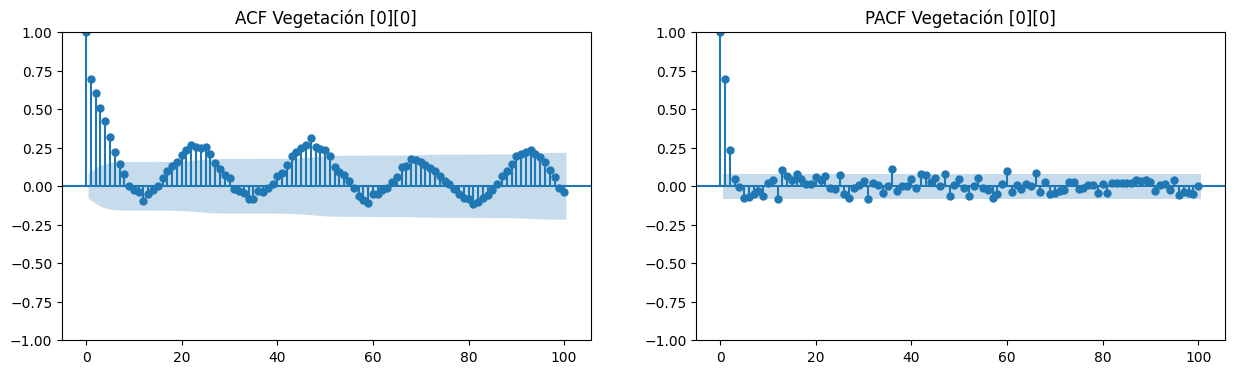

In [4]:
autocorrelacion = Autocorrelacion(vegetacion_cubo.tiempo, vegetacion_cubo.datos[0, 0,:], "Vegetación [0][0]")
autocorrelacion.grafico()

### Ajuste SARIMA 

In [5]:
modelo = SARIMAX(
    vegetacion_cubo.datos[0, 0, :],
    order=(2, 0, 0),
    seasonal_order=(2, 0, 2, 23),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste = modelo.fit(disp=False)
print(ajuste.summary())

                                        SARIMAX Results                                        
Dep. Variable:                                       y   No. Observations:                  604
Model:             SARIMAX(2, 0, 0)x(2, 0, [1, 2], 23)   Log Likelihood                1569.714
Date:                                 Sun, 25 Oct 2026   AIC                          -3123.428
Time:                                         10:40:28   BIC                          -3088.862
Sample:                                              0   HQIC                         -3109.927
                                                 - 604                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0017      0.001      1.384      0.166      -0.001       0

### Residuos

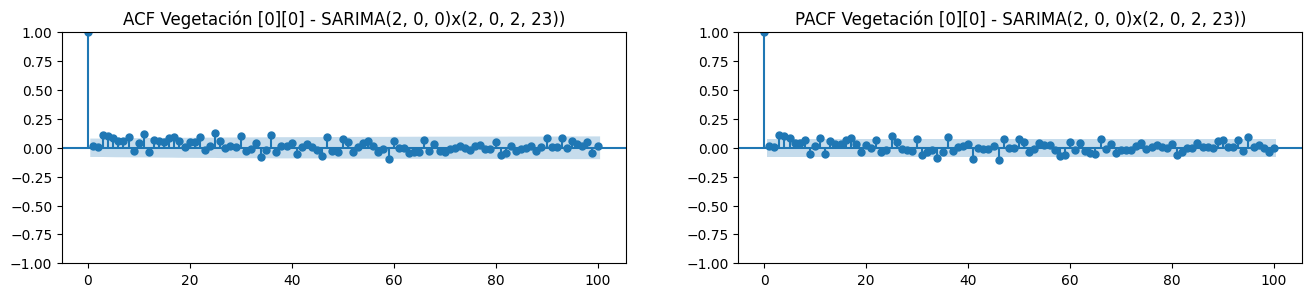

{'acf significativos': [(3, np.float64(0.114)),
  (4, np.float64(0.103)),
  (11, np.float64(0.116)),
  (25, np.float64(0.129)),
  (30, np.float64(0.104)),
  (36, np.float64(0.111))],
 'pacf_significativos': [(3, np.float64(0.114)),
  (4, np.float64(0.101)),
  (25, np.float64(0.102)),
  (36, np.float64(0.092)),
  (41, np.float64(-0.099)),
  (46, np.float64(-0.107)),
  (95, np.float64(0.096))]}

In [6]:
ajuste_vegetacion = AjusteSARIMA(vegetacion_cubo.datos[0, 0, :], ajuste, "Vegetación [0][0] - SARIMA(2, 0, 0)x(2, 0, 2, 23))")
ajuste_vegetacion.graficos_residuos()

## Ajuste SARIMA Temperatura [0][0]

### Autocorrelación

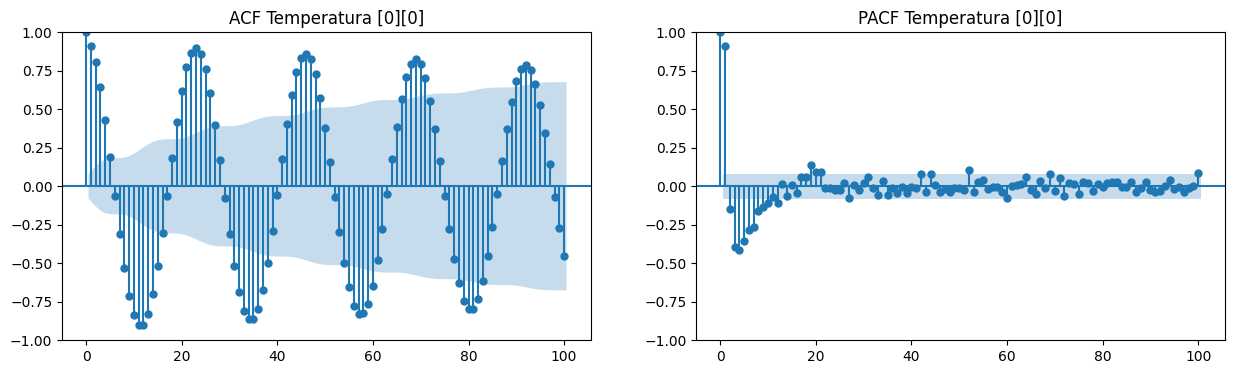

In [8]:
autocorrelacion = Autocorrelacion(temperatura_cubo.tiempo, temperatura_cubo.datos[0, 0,:], "Temperatura [0][0]")
autocorrelacion.grafico()

### Ajuste SARIMA

In [21]:
modelo = SARIMAX(
    temperatura_cubo.datos[0, 0, :],
    order=(1, 0, 1),
    seasonal_order=(4, 0, 0, 23),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste = modelo.fit(disp=False)
print(ajuste.summary())

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  604
Model:             SARIMAX(1, 0, 1)x(4, 0, [], 23)   Log Likelihood               -1011.821
Date:                             Sun, 25 Oct 2026   AIC                           2039.642
Time:                                     10:53:34   BIC                           2073.533
Sample:                                          0   HQIC                          2052.928
                                             - 604                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0515      0.065      0.790      0.430      -0.076       0.179
ar.L1          0.7521      

### Residuos

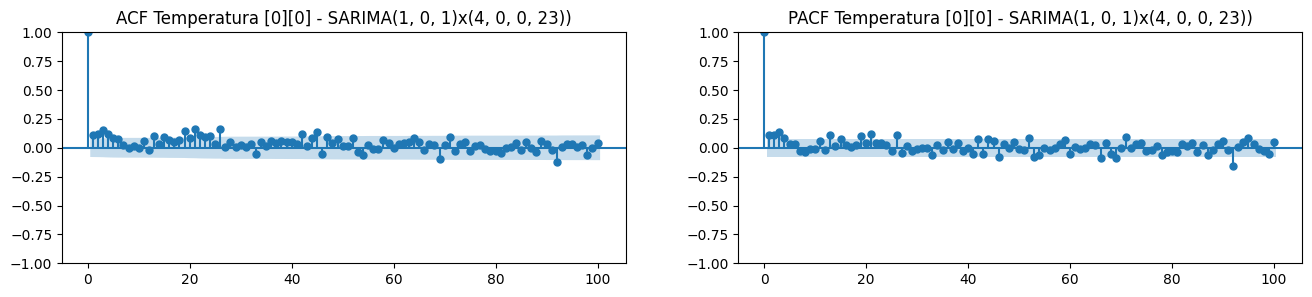

{'acf significativos': [(1, np.float64(0.108)),
  (2, np.float64(0.118)),
  (3, np.float64(0.155)),
  (4, np.float64(0.121)),
  (13, np.float64(0.104)),
  (19, np.float64(0.142)),
  (21, np.float64(0.158)),
  (22, np.float64(0.109)),
  (26, np.float64(0.164)),
  (42, np.float64(0.118)),
  (45, np.float64(0.134)),
  (92, np.float64(-0.124))],
 'pacf_significativos': [(1, np.float64(0.108)),
  (2, np.float64(0.108)),
  (3, np.float64(0.135)),
  (13, np.float64(0.11)),
  (19, np.float64(0.1)),
  (21, np.float64(0.121)),
  (26, np.float64(0.111)),
  (66, np.float64(-0.093)),
  (71, np.float64(0.095)),
  (92, np.float64(-0.157))]}

In [22]:
ajuste_temperatura = AjusteSARIMA(temperatura_cubo.datos[0, 0, :], ajuste, "Temperatura [0][0] - SARIMA(1, 0, 1)x(4, 0, 0, 23))")
ajuste_temperatura.graficos_residuos()